# Milestone 1: First API requests

In [56]:
# Milestone 1: fetch series info
import requests
import pandas as pd
import time
import matplotlib.pyplot as plt
import os
os.makedirs("charts", exist_ok=True)

BASE_URL = "https://external-api.kalshi.com/trade-api/v2"
DOWNLOAD = False

response = requests.get(BASE_URL + "/series/KXHIGHNY")
print(response.status_code)
data = response.json()
print(data["series"]["title"], "-", data["series"]["category"])

200
Highest temperature in NYC - Climate and Weather


In [57]:
# Milestone 1: fetch 5 settled markets
MARKET_URL = BASE_URL + "/markets"
markets_data = requests.get(MARKET_URL, params={"series_ticker": "KXHIGHNY", "status": "settled", "limit": 5}).json()

for market in markets_data["markets"]:
    print(f"{market['ticker']}: {market['title']} {market['result']}")

KXHIGHNY-26OCT14-T85: Will the maximum temperature be >85° on Oct 14, 2026? no
KXHIGHNY-26OCT14-T78: Will the maximum temperature be <78° on Oct 14, 2026? yes
KXHIGHNY-26OCT14-B84.5: Will the maximum temperature be 84-85° on Oct 14, 2026? no
KXHIGHNY-26OCT14-B82.5: Will the maximum temperature be 82-83° on Oct 14, 2026? no
KXHIGHNY-26OCT14-B80.5: Will the maximum temperature be 80-81° on Oct 14, 2026? no


# Milestone 2: find out what categories exist


## Choosing series

In [91]:
CATEGORIES_URL = BASE_URL + "/series"
categories = set()
series_data = requests.get(CATEGORIES_URL).json()
for s in series_data["series"]:
    categories.add(s["category"])
print(categories)


{'Culture', 'Mentions', 'Entertainment', 'World', 'Commodities', 'Business', 'Climate and Weather', 'Companies', 'Science and Technology', 'Education', 'Health', 'Economics', 'Exotics', 'Crypto', 'Politics', 'Elections', 'Sports', 'Transportation', 'Social', 'Financials'}


In [83]:
def top_series(category, n=15):
    print(f"Top {n} {category} Series by Volume")
    category_data = requests.get(CATEGORIES_URL, params={"category": category, "include_volume": True}).json()
    print(len(category_data["series"]))
    top = sorted(category_data["series"], key=lambda s: float(s["volume_fp"]), reverse=True)

    for series in top[:n]:
        print(series["ticker"], series["title"], series["volume_fp"])

top_series("Climate and Weather")
top_series("Elections")
top_series("Financials")


Top 15 Climate and Weather Series by Volume
424
KXHIGHLAX Highest temperature in Los Angeles 181324599.00
KXHIGHNY Highest temperature in NYC 149074568.00
KXHIGHCHI Highest temperature in Chicago 113029241.00
KXHIGHMIA Highest temperature in Miami 103517882.00
KXHIGHAUS Highest temperature in Austin 78821467.00
KXRAIN Where will it rain daily 58925371.00
KXHIGHDEN Highest temperature in Denver 52047958.00
KXHIGHPHIL Highest temperature in Philadelphia 42774183.00
KXRAINNYC NYC rain 30548636.00
KXHIGHTSFO San Francisco High Temperature Daily 19735017.00
KXHIGHTPHX Phoenix High Temperature Daily 18780801.00
KXHIGHTSEA Seattle Maximum Temperature Daily 17648558.00
KXHIGHTATL Atlanta Max Temperature 17561814.00
KXHIGHTBOS Boston Maximum Daily Temperature 16635889.00
KXTEMPMIAH Hourly Directional Miami Temperature 16021015.00
Top 15 Elections Series by Volume
2304
PRES Presidential elections 535948943.00
KXPRESNOMD Democratic Primary winner 239431072.00
POPVOTEMOV Popular vote margin of vic

In [84]:
def check_lifetime(series_ticker):
    print(f"5 Settled Markets from {series_ticker}")
    settled_markets = requests.get(MARKET_URL, params={"series_ticker": series_ticker, "status": "settled", "limit": 5}).json()
    for market in settled_markets["markets"]:
        diff = pd.to_datetime(market["close_time"]) - pd.to_datetime(market["open_time"])
        print(market["ticker"], diff)

check_lifetime("KXNBAGAME")
check_lifetime("KXNFLGAME")
check_lifetime("KXNHLGAME")
check_lifetime("KXMLBGAME")

5 Settled Markets from KXNBAGAME
KXNBAGAME-26OCT12LIOPOR-POR 0 days 21:55:11
KXNBAGAME-26OCT12LIOPOR-LIO 0 days 21:55:11
KXNBAGAME-26OCT14DENLAC-LAC 7 days 02:20:50.185091
KXNBAGAME-26OCT14DENLAC-DEN 7 days 02:20:50.185091
KXNBAGAME-26OCT14PHXSAS-SAS 7 days 02:27:31.962811
5 Settled Markets from KXNFLGAME
KXNFLGAME-26OCT12BUFLAR-LAR 13 days 23:42:50
KXNFLGAME-26OCT12BUFLAR-BUF 13 days 23:42:50
KXNFLGAME-26OCT11BALATL-BAL 12 days 23:42:15
KXNFLGAME-26OCT11BALATL-ATL 12 days 23:42:15
KXNFLGAME-26OCT11CHIGB-GB 12 days 16:02:30
5 Settled Markets from KXNHLGAME
KXNHLGAME-26OCT14DALCOL-DAL 7 days 02:19:35
KXNHLGAME-26OCT14DALCOL-COL 7 days 02:19:35
KXNHLGAME-26OCT14MTLWSH-WSH 7 days 01:19:58
KXNHLGAME-26OCT14MTLWSH-MTL 7 days 01:19:58
KXNHLGAME-26OCT13BOSSJ-SJ 7 days 01:43:54
5 Settled Markets from KXMLBGAME
KXMLBGAME-26OCT132000CLETB-TB 2 days 23:30:21
KXMLBGAME-26OCT132000CLETB-CLE 2 days 23:30:21
KXMLBGAME-26OCT122000CLETB-TB 1 days 23:44:51
KXMLBGAME-26OCT122000CLETB-CLE 1 days 23:44:51


## Downloading

In [85]:
#Used to find cutoff date for historical vs live markets
cutoff = requests.get(BASE_URL + "/historical/cutoff").json()
CUTOFF = cutoff["market_settled_ts"]
print(cutoff)

{'market_positions_last_updated_ts': '2026-08-16T00:00:00Z', 'market_settled_ts': '2026-08-16T00:00:00Z', 'orders_updated_ts': '2026-10-01T00:00:00Z', 'trades_created_ts': '2026-08-16T00:00:00Z'}


In [86]:
def get_settled_markets(series_ticker, url):
    all_markets = []
    cursor = None
    while True:
        params = {"series_ticker": series_ticker, "limit": 1000}
        if url == MARKET_URL:
            params["status"] = "settled"
        if cursor:
            params["cursor"] = cursor
        data = requests.get(url, params=params).json()
        all_markets.extend(data["markets"])
        cursor = data["cursor"]
        if not cursor:
            break
        time.sleep(0.2)
    return all_markets

HIST_URL = BASE_URL + "/historical/markets"
nfl_live = get_settled_markets("KXNFLGAME", MARKET_URL)
nfl_hist = get_settled_markets("KXNFLGAME", HIST_URL)
print(len(nfl_live))
print(len(nfl_hist))

254
696


In [87]:
if DOWNLOAD:
    SERIES = ["KXNFLGAME", "KXNBAGAME", "KXMLBGAME", "KXNHLGAME"]
    all_markets = []
    for ticker in SERIES:
        combined = get_settled_markets(ticker, MARKET_URL) + get_settled_markets(ticker, HIST_URL)
        for market in combined:
            market["series"] = ticker
        all_markets.extend(combined)
        print(ticker, len(combined))

    print(len(all_markets))

In [88]:
if DOWNLOAD:
    df = pd.DataFrame(all_markets)
    df.to_csv("markets.csv", index=False)
    print(df.shape)
    print(df["series"].value_counts())
    print(df["ticker"].duplicated().sum())

In [89]:
#Checking which series have dupes
if DOWNLOAD:
    dupes = df[df["ticker"].duplicated(keep=False)]
    print(len(dupes))
    print(dupes["series"].value_counts())

In [90]:
#Dropping dupes
if DOWNLOAD:
    df = df.drop_duplicates(subset="ticker")
    print(df.shape)
    print(df["ticker"].duplicated().sum())
    df.to_csv("markets.csv", index=False)

# Milestone 3: Clean the data

In [67]:
df = pd.read_csv("markets.csv", low_memory=False)
print(df.shape)

(16688, 46)


In [68]:
#See types
df.dtypes

can_close_early                bool
close_time                      str
created_time                    str
custom_strike                   str
early_close_condition           str
event_ticker                    str
exchange_index                int64
expected_expiration_time        str
expiration_time                 str
expiration_value                str
last_price_dollars          float64
latest_expiration_time          str
market_type                     str
no_ask_dollars              float64
no_bid_dollars              float64
no_sub_title                    str
notional_value_dollars      float64
occurrence_datetime             str
open_interest_fp            float64
open_time                       str
previous_price_dollars      float64
previous_yes_ask_dollars    float64
previous_yes_bid_dollars    float64
price_level_structure           str
price_ranges                    str
result                          str
rules_primary                   str
rules_secondary             

In [69]:
#Clean result column
df = df[df["result"].isin(["yes", "no"])]
print(df.shape)

(16644, 46)


In [70]:
#Clean times
df["close_time"] = pd.to_datetime(df["close_time"], format="ISO8601")
df["open_time"] = pd.to_datetime(df["open_time"], format="ISO8601")

df.dtypes

can_close_early                            bool
close_time                  datetime64[us, UTC]
created_time                                str
custom_strike                               str
early_close_condition                       str
event_ticker                                str
exchange_index                            int64
expected_expiration_time                    str
expiration_time                             str
expiration_value                            str
last_price_dollars                      float64
latest_expiration_time                      str
market_type                                 str
no_ask_dollars                          float64
no_bid_dollars                          float64
no_sub_title                                str
notional_value_dollars                  float64
occurrence_datetime                         str
open_interest_fp                        float64
open_time                   datetime64[us, UTC]
previous_price_dollars                  

In [71]:
#Adding an outcome column
df["outcome"] = (df["result"] == "yes").astype(int)
df["outcome"].mean()

np.float64(0.49975967315549147)

In [72]:
#Clean volume
df = df[df["volume_fp"] > 0]
df.shape

(16631, 47)

In [73]:
df["event_ticker"].value_counts().value_counts()

count
2    8315
1       1
Name: count, dtype: int64

In [74]:
#Shuffle rows
df = df.sample(frac=1, random_state=42).drop_duplicates(subset="event_ticker")
print(df.shape)
print(df["outcome"].mean())

(8316, 47)
0.5018037518037518


## Market lifetimes

In [77]:
df["lifetime_hours"] = (df["close_time"] - df["open_time"]).dt.total_seconds() / 3600
print(df["lifetime_hours"].head())

df.groupby("series")["lifetime_hours"].describe()

4532     74.324444
13836    73.571944
12432     8.639514
9569     14.052059
4826     74.244444
Name: lifetime_hours, dtype: float64


,count,mean,std,min,25%,50%,75%,max
series,,,,,,,,
KXMLBGAME,4669.0,60.185110,321.889507,3.407914,14.065171,74.087500,74.657222,8165.593611
KXNBAGAME,1494.0,63.876301,28.834693,11.193531,57.152254,58.661776,59.734322,270.805833
KXNFLGAME,452.0,536.461266,704.264456,73.603624,225.330945,292.375144,315.571792,2938.188611
KXNHLGAME,1701.0,76.494451,29.614333,17.243503,67.988736,69.065031,73.241944,262.850833


In [96]:
#Save to clean csv
df.to_csv("clean_markets.csv", index=False)

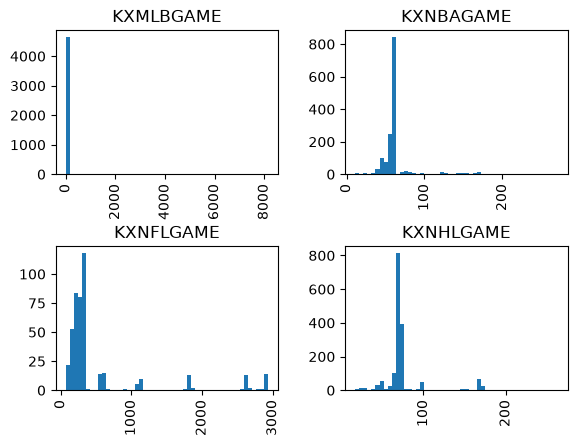

In [78]:
df.hist(column="lifetime_hours", by="series", bins=50)
plt.show()

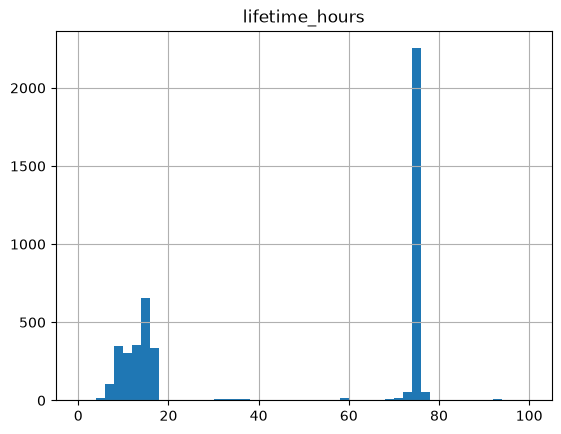

In [79]:
mlb = df[df["series"] == "KXMLBGAME"]
mlb.hist(column="lifetime_hours", bins=50, range=(0, 100))
plt.show()

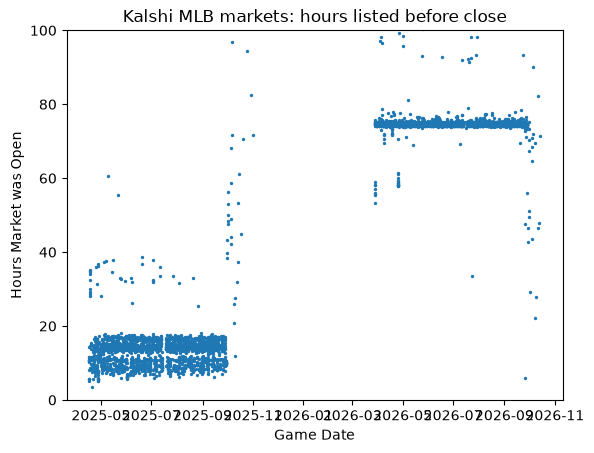

In [80]:
plt.scatter(mlb["close_time"], mlb["lifetime_hours"], s=2)
plt.ylim(0, 100)
plt.title("Kalshi MLB markets: hours listed before close")
plt.xlabel("Game Date")
plt.ylabel("Hours Market was Open")
plt.savefig("charts/mlb_listing_change.png")
plt.show()

In [95]:
#24 hour filter
df = df[df["lifetime_hours"] >= 24]
print(df.shape)
print(df["series"].value_counts())

(6166, 48)
series
KXMLBGAME    2543
KXNHLGAME    1692
KXNBAGAME    1479
KXNFLGAME     452
Name: count, dtype: int64


# Milestone 4

In [ ]:
#scratch cell
row = df.iloc[0]
print(row["ticker"], row["series"], row["close_time"])

close_ts = int(row["close_time"].timestamp())
start_ts = close_ts - 48 * 3600

if row["close_time"] < pd.to_datetime(CUTOFF):
    url = BASE_URL + f"/historical/markets/{row['ticker']}/candlesticks"
else:
    url = BASE_URL + f"/series/{row['series']}/markets/{row['ticker']}/candlesticks"

candle_data = requests.get(url, params={"start_ts": start_ts, "end_ts": close_ts, "period_interval": 60}).json()

print(len(candle_data["candlesticks"]))
print(candle_data["candlesticks"][0])

KXMLBGAME-26SEP061610ATHSEA-SEA KXMLBGAME 2026-09-06 22:44:28+00:00
44
{'end_period_ts': 1788562800, 'open_interest_fp': '21.00', 'price': {'previous_dollars': '0.6600'}, 'volume_fp': '0.00', 'yes_ask': {'close_dollars': '0.6700', 'high_dollars': '0.6700', 'low_dollars': '0.6400', 'open_dollars': '0.6600'}, 'yes_bid': {'close_dollars': '0.6600', 'high_dollars': '0.6600', 'low_dollars': '0.6300', 'open_dollars': '0.6300'}}


In [ ]:
def get_price_24h(row):
    close_ts = int(row["close_time"].timestamp())
    target_ts = close_ts - 24 *3600
    start_ts = target_ts -3 * 3600
    end_ts = target_ts + 3 * 3600
    if row["close_time"] < pd.to_datetime(CUTOFF):
        url = BASE_URL + f"/historical/markets/{row['ticker']}/candlesticks"
    else:
        url = BASE_URL + f"/series/{row['series']}/markets/{row['ticker']}/candlesticks"
    
    candle_data = requests.get(url, params={"start_ts": start_ts, "end_ts": end_ts, "period_interval": 60}).json()
    candles = candle_data["candlesticks"]    
    if not candles:
        return None
    closest = min(candles, key=lambda c: abs(c["end_period_ts"] - target_ts))

    price = closest["price"].get("close")
    if price is None:
        price = closest["price"].get("close_dollars")
    if price is None:
        bid = closest["yes_bid"].get("close")
        ask = closest["yes_ask"].get("close")
        price = (float(bid) + float(ask)) / 2
    return float(price)


In [100]:
print(get_price_24h(df.iloc[0]))

6
